# IBM Fermi-Hubbard paper (arXiv:2605.04025) — Figs. 2 & 3

Standard (direct-site) encoding via `StandardFermiHubbard`. The driver
functions live in `ibm_paper_figures.py`; this notebook just wires up the
parameters and shows the resulting figures inline.

In [12]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt

from models.qutip_model_encodings import StandardFermiHubbard, DomainWallFermiHubbard
from ibm_paper_figures import (
    neel_state,
    occupations,
    charge_tracer,
    spin_tracer,
    detect_wavefront_velocity,
    run_fig2,
    run_fig3,
)

%matplotlib inline

## Single quench: Néel + central vacancy

Analog of the highlighted cell from `hexagonal_test.ipynb`, but using the
Néel-with-vacancy initial state from the paper and going through the
tracer-correlator pipeline.

In [18]:
chain_length = 8
t = 1.0
U = 1.0
e = 0.0
T = 9.0
dt = 0.01

nsteps = int(T / dt)
t_list = np.linspace(0.0, T, nsteps)
vacancy_site = chain_length // 2

model = DomainWallFermiHubbard(chain_length, t, U, e, T, nsteps, J=t*20)
neel_state(model, vacancy_site=vacancy_site)

pauli_strings = ['ZZ']
sim, measurements = model.run(pauli_strings=pauli_strings)

n_up, n_down = occupations(measurements['ZZ'], chain_length)
Cc = charge_tracer(n_up, n_down)
Cs = spin_tracer(model, sim, vacancy_site)

vc, _ = detect_wavefront_velocity(Cc, t_list, vacancy_site, force_origin=True)
vs, _ = detect_wavefront_velocity(Cs, t_list, vacancy_site, force_origin=True)
print(f'v_c = {vc:.3f},  v_s = {vs:.3f},  v_c/v_s = {vc / vs:.3f}')

v_c = 0.558,  v_s = 0.624,  v_c/v_s = 0.894


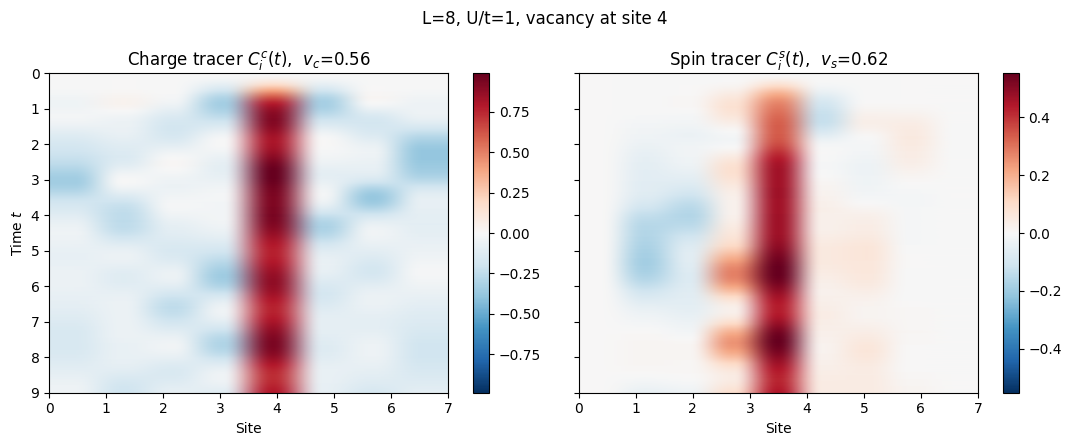

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

vmax = np.max(np.abs(Cc)) or 1.0
im0 = axes[0].imshow(Cc, aspect='auto', origin='upper',
                     extent=[0, chain_length - 1, T, 0],
                     cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Charge tracer $C^c_i(t)$,  $v_c$={vc:.2f}')
axes[0].set_xlabel('Site'); axes[0].set_ylabel('Time $t$')
plt.colorbar(im0, ax=axes[0])

vmax = np.max(np.abs(Cs)) or 1.0
im1 = axes[1].imshow(Cs, aspect='auto', origin='upper',
                     extent=[0, chain_length - 1, T, 0],
                     cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Spin tracer $C^s_i(t)$,  $v_s$={vs:.2f}')
axes[1].set_xlabel('Site')
plt.colorbar(im1, ax=axes[1])

fig.suptitle(f'L={chain_length}, U/t={U:g}, vacancy at site {vacancy_site}')
fig.tight_layout()
plt.show()

## Full Fig. 2 sweep over $U/t$

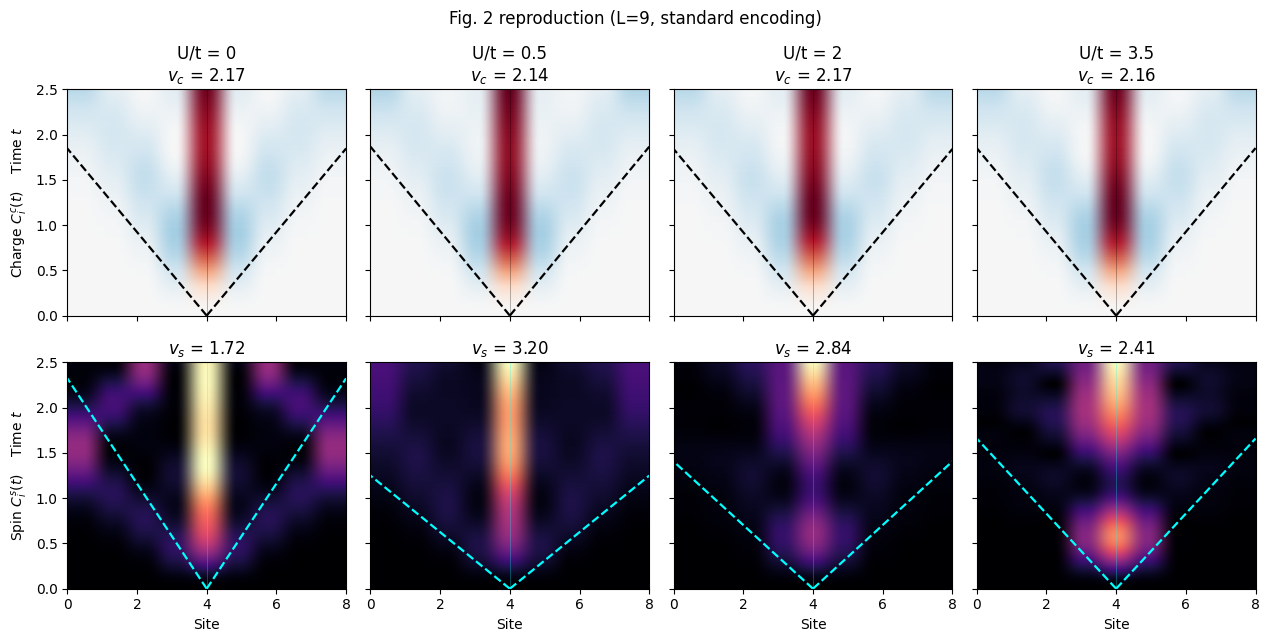

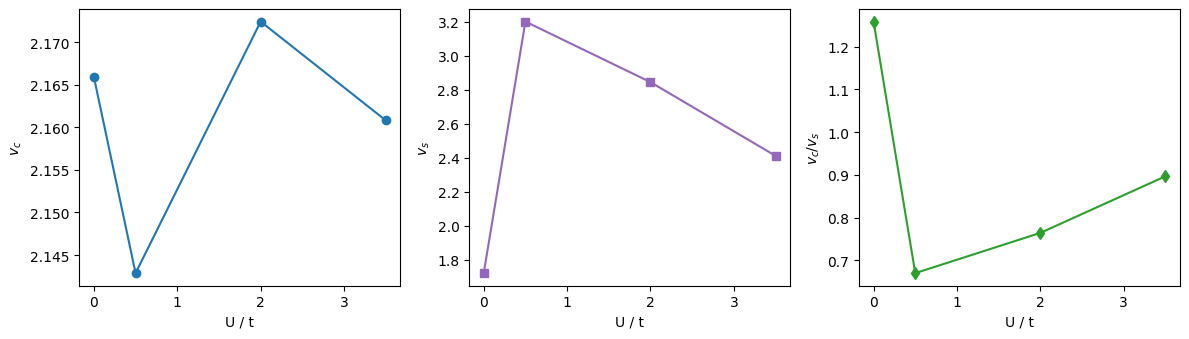

U= 0.00   v_c=2.166   v_s=1.720   v_c/v_s=1.259
U= 0.50   v_c=2.143   v_s=3.200   v_c/v_s=0.670
U= 2.00   v_c=2.172   v_s=2.844   v_c/v_s=0.764
U= 3.50   v_c=2.161   v_s=2.410   v_c/v_s=0.897


In [ ]:
outdir = os.path.abspath('./ibm_paper_outputs')
os.makedirs(outdir, exist_ok=True)

fig2_results = run_fig2(
    chain_length=8,
    U_values=(0.0, 0.5, 2.0, 3.5),
    t_hop=0.5, e=0.0, T=2.5, nsteps=250,
    outdir=outdir,
)
plt.show()

for U, _, _, vc, vs in fig2_results:
    print(f'U={U:5.2f}   v_c={vc:.3f}   v_s={vs:.3f}   v_c/v_s={vc/vs:.3f}')

## Fig. 3: Néel quench, with and without a central vacancy

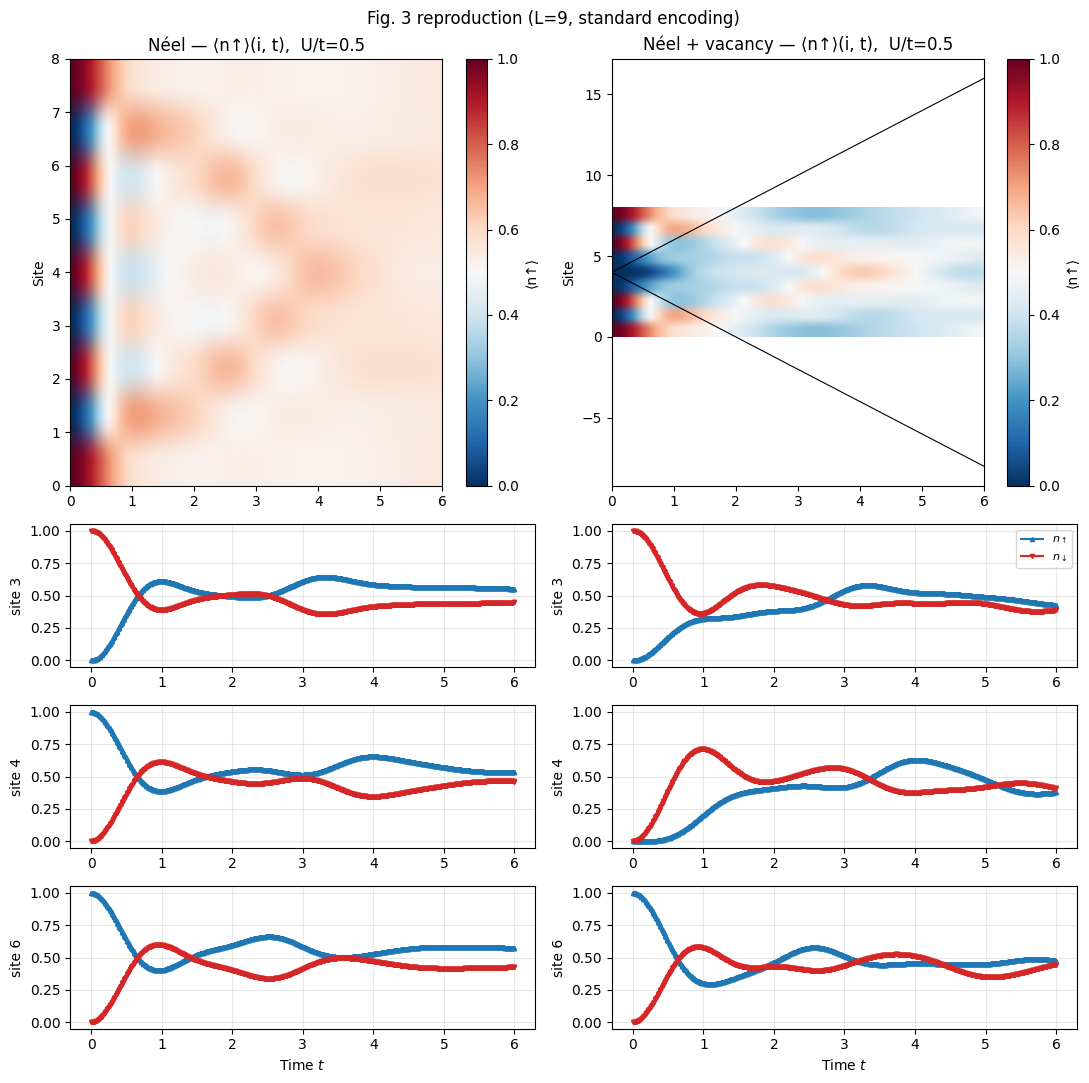

In [5]:
run_fig3(
    chain_length=9,
    U=0.5, t_hop=0.5, e=0.0,
    T=6.0, nsteps=600,
    outdir=outdir,
)
plt.show()